**The Following are the class**

In [ ]:
# Import Path to work with folders and file paths.
from pathlib import Path

# Import pandas for tabular data analysis.
import pandas as pd

# Import NumPy for numerical calculations.
import numpy as np

# Import Matplotlib for plotting charts.
import matplotlib.pyplot as plt

# Import PIL to open and inspect images.
from PIL import Image, ImageStat, UnidentifiedImageError

# Import Counter to count class labels.
from collections import Counter

# Import os for file-related operations.
import os

# Import hashlib for duplicate detection.
import hashlib

In [ ]:
from pathlib import Path
# Point to the extracted, non-augmented dataset.
DATASET_DIR = Path(
    "/content/drive/MyDrive/diseases_dataset_without_augmentation"
)

# Verify that the path exists.
print("Dataset exists:", DATASET_DIR.exists())

# Display the first 20 items in the dataset folder.
if DATASET_DIR.exists():
    for item in sorted(DATASET_DIR.iterdir())[::]:
        print(item.name)

Dataset exists: True
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Cherry___Powdery_mildew
Cherry___healthy
Corn___Cercospora_leaf_spot Gray_leaf_spot
Corn___Common_rust
Corn___Northern_Leaf_Blight
Corn___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy


**Number of images in each class**

In [ ]:
# Define supported image file extensions.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Create an empty dictionary to store class counts.
class_counts = {}

# Loop through every immediate subfolder.
for class_dir in sorted(DATASET_DIR.iterdir()):

    # Process only directories.
    if class_dir.is_dir():

        # Count supported image files recursively.
        image_count = sum(
            1
            for file in class_dir.rglob("*")
            if file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        )

        # Store the count using the folder name as the label.
        class_counts[class_dir.name] = image_count

# Convert the dictionary to a DataFrame.
class_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image_Count"]
)

# Sort classes by image count.
class_df = class_df.sort_values(
    by="Image_Count",
    ascending=False
).reset_index(drop=True)

# Display the class counts.
display(class_df)

# Calculate the total number of images.
print("Total classes:", len(class_df))
print("Total images:", class_df["Image_Count"].sum())

,Class,Image_Count
0,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357
1,Peach___Bacterial_spot,2297
2,Tomato___Bacterial_spot,2127
3,Tomato___Late_blight,1909
4,Tomato___Septoria_leaf_spot,1771
5,Tomato___Spider_mites Two-spotted_spider_mite,1676
6,Apple___healthy,1645
7,Tomato___healthy,1591
8,"Pepper,_bell___healthy",1478
9,Tomato___Target_Spot,1404


Total classes: 33
Total images: 40000


**Clearly their is imbalance in each calss**

In [ ]:
# Calculate summary statistics for the image counts.
print(class_df["Image_Count"].describe())

# Identify the class with the most images.
largest_class = class_df.loc[
    class_df["Image_Count"].idxmax()
]

# Identify the class with the fewest images.
smallest_class = class_df.loc[
    class_df["Image_Count"].idxmin()
]

# Display the largest class.
print("\nLargest class:")
print(largest_class)

# Display the smallest class.
print("\nSmallest class:")
print(smallest_class)

# Calculate the imbalance ratio.
imbalance_ratio = (
    largest_class["Image_Count"] /
    smallest_class["Image_Count"]
)

print("\nLargest-to-smallest class ratio:", round(imbalance_ratio, 2))

count      33.000000
mean     1212.121212
std       917.981609
min       152.000000
25%       630.000000
50%      1052.000000
75%      1478.000000
max      5357.000000
Name: Image_Count, dtype: float64

Largest class:
Class          Tomato___Tomato_Yellow_Leaf_Curl_Virus
Image_Count                                      5357
Name: 0, dtype: object

Smallest class:
Class          Potato___healthy
Image_Count                 152
Name: 32, dtype: object

Largest-to-smallest class ratio: 35.24


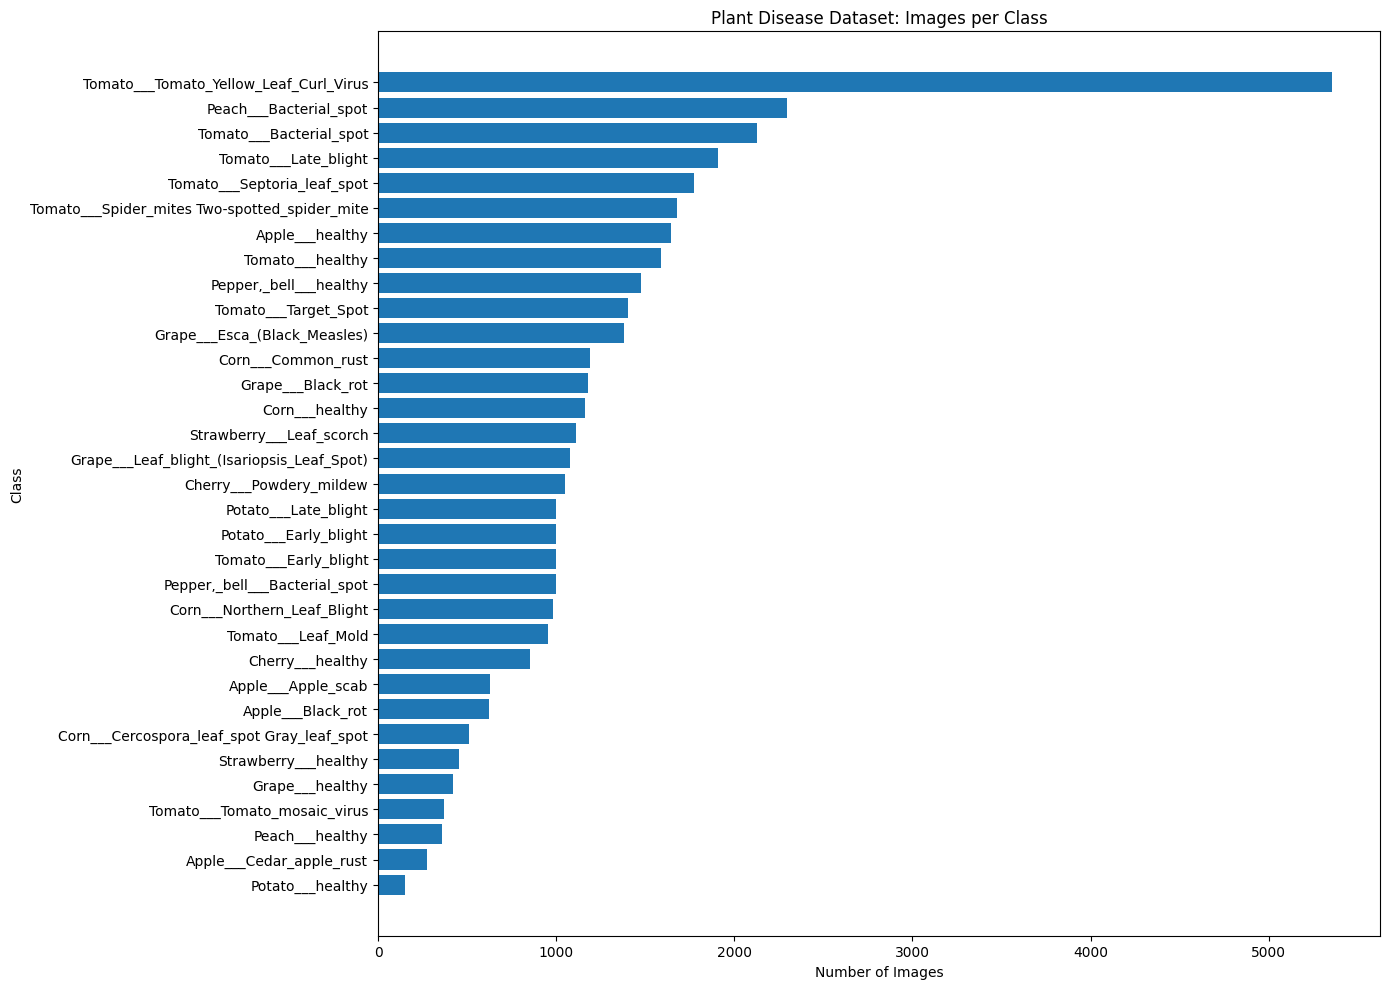

In [ ]:
# Create a figure large enough to display all class names.
plt.figure(figsize=(14, 10))

# Plot image counts for each class.
plt.barh(
    class_df["Class"],
    class_df["Image_Count"]
)

# Put the largest class at the top.
plt.gca().invert_yaxis()

# Add chart title and axis labels.
plt.title("Plant Disease Dataset: Images per Class")
plt.xlabel("Number of Images")
plt.ylabel("Class")

# Adjust spacing so labels are readable.
plt.tight_layout()

# Display the chart.
plt.show()

 Tomato___Tomato_Yellow_Leaf_Curl_Virus calss has the highest number of images
 potato_healthy has the least number of images

In [ ]:
# Calculate the percentage of the dataset represented by each class.
class_df["Percentage"] = (
    class_df["Image_Count"] /
    class_df["Image_Count"].sum()
) * 100

# Display the most represented classes.
display(class_df.head(10))

# Display the least represented classes.
display(class_df.tail(10))

,Class,Image_Count,Percentage
0,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,13.3925
1,Peach___Bacterial_spot,2297,5.7425
2,Tomato___Bacterial_spot,2127,5.3175
3,Tomato___Late_blight,1909,4.7725
4,Tomato___Septoria_leaf_spot,1771,4.4275
5,Tomato___Spider_mites Two-spotted_spider_mite,1676,4.1900
6,Apple___healthy,1645,4.1125
7,Tomato___healthy,1591,3.9775
8,"Pepper,_bell___healthy",1478,3.6950
9,Tomato___Target_Spot,1404,3.5100


,Class,Image_Count,Percentage
23,Cherry___healthy,854,2.1350
24,Apple___Apple_scab,630,1.5750
25,Apple___Black_rot,621,1.5525
26,Corn___Cercospora_leaf_spot Gray_leaf_spot,513,1.2825
27,Strawberry___healthy,456,1.1400
28,Grape___healthy,423,1.0575
29,Tomato___Tomato_mosaic_virus,373,0.9325
30,Peach___healthy,360,0.9000
31,Apple___Cedar_apple_rust,275,0.6875
32,Potato___healthy,152,0.3800


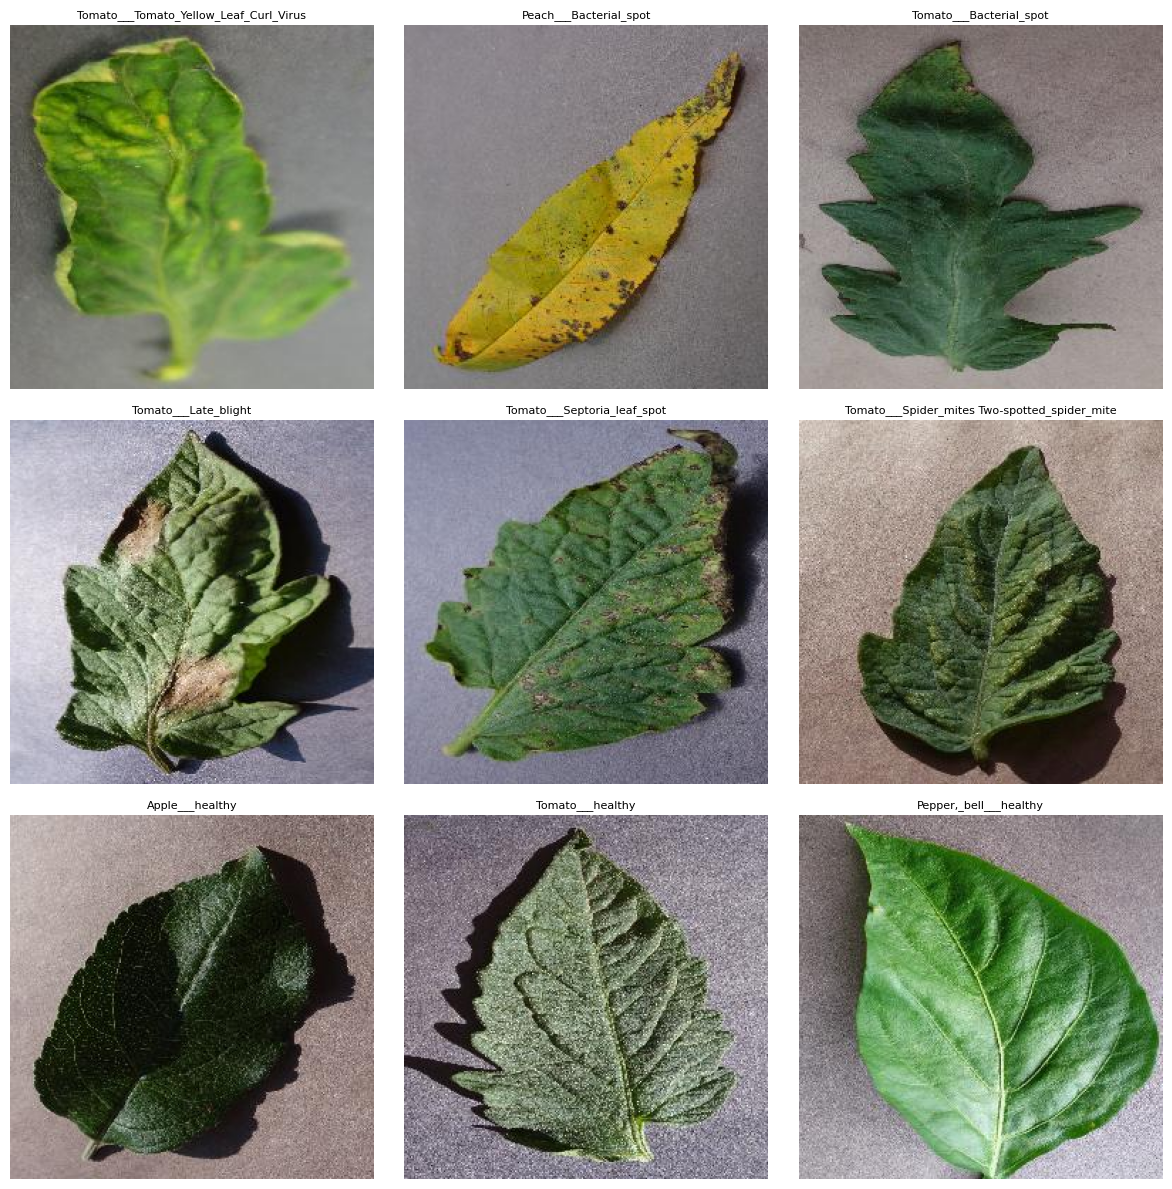

In [ ]:
# Set a random seed so the sample is reproducible.
rng = np.random.default_rng(42)

# Select up to 9 classes for the sample grid.
sample_classes = class_df["Class"].head(9).tolist()

# Create a 3-by-3 grid of image plots.
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

# Flatten the axes array for easy iteration.
axes = axes.flatten()

# Loop through the selected classes and plot one random image per class.
for ax, class_name in zip(axes, sample_classes):

    # Get the current class directory.
    class_dir = DATASET_DIR / class_name

    # Find all supported images in this class.
    image_files = [
        file for file in class_dir.rglob("*")
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    # Skip classes with no images.
    if not image_files:
        ax.axis("off")
        continue

    # Select one image randomly.
    image_path = rng.choice(image_files)

    # Open the image and convert it to RGB.
    with Image.open(image_path) as img:
        image = img.convert("RGB")

    # Display the image.
    ax.imshow(image)

    # Display the class name as the plot title.
    ax.set_title(class_name, fontsize=8)

    # Hide the axes.
    ax.axis("off")

# Hide unused plots if fewer than 9 classes are available.
for ax in axes[len(sample_classes):]:
    ax.axis("off")

# Adjust spacing.
plt.tight_layout()

# Display the grid.
plt.show()

**Sample Images from data**

In [ ]:
# Create lists to collect image properties.
image_properties = []

# Inspect all images in every class folder.
for class_dir in sorted(DATASET_DIR.iterdir()):

    # Ignore files directly inside the dataset root.
    if not class_dir.is_dir():
        continue

    # Iterate through the image files.
    for image_path in class_dir.rglob("*"):

        # Ignore unsupported files.
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        # Open the image safely.
        try:
            with Image.open(image_path) as img:

                # Store its properties.
                image_properties.append({
                    "Class": class_dir.name,
                    "File": str(image_path),
                    "Width": img.width,
                    "Height": img.height,
                    "Mode": img.mode,
                    "Format": img.format
                })

        # Skip unreadable images for this inspection.
        except (OSError, UnidentifiedImageError):
            continue

# Convert the collected properties to a DataFrame.
image_df = pd.DataFrame(image_properties)

# Display the first few rows.
display(image_df.head())

# Summarize image dimensions.
print("Image dimensions:")
display(image_df[["Width", "Height"]].describe())

# Count image color modes.
print("Color modes:")
display(image_df["Mode"].value_counts())

# Count image formats.
print("File formats:")
display(image_df["Format"].value_counts())

# Check the number of distinct image dimensions.
print(
    "Distinct width-height combinations:",
    image_df[["Width", "Height"]].drop_duplicates().shape[0]
)

In [ ]:
# Group image properties by class and summarize them.
class_report = image_df.groupby("Class").agg(
    Total_Images=("File", "count"),
    Unique_Widths=("Width", "nunique"),
    Unique_Heights=("Height", "nunique"),
    Color_Modes=("Mode", lambda x: ", ".join(sorted(x.unique()))),
    File_Formats=("Format", lambda x: ", ".join(sorted(x.unique())))
).reset_index()

# Display all classes instead of only the first five.
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(class_report)

,Class,Total_Images,Unique_Widths,Unique_Heights,Color_Modes,File_Formats
0,Apple___Apple_scab,630,1,1,RGB,JPEG
1,Apple___Black_rot,621,1,1,RGB,JPEG
2,Apple___Cedar_apple_rust,275,1,1,RGB,JPEG
3,Apple___healthy,1645,1,1,RGB,JPEG
4,Cherry___Powdery_mildew,1052,1,1,RGB,JPEG
5,Cherry___healthy,854,1,1,RGB,JPEG
6,Corn___Cercospora_leaf_spot Gray_leaf_spot,513,1,1,RGB,JPEG
7,Corn___Common_rust,1192,1,1,RGB,JPEG
8,Corn___Northern_Leaf_Blight,985,1,1,RGB,JPEG
9,Corn___healthy,1162,1,1,RGB,JPEG


From this we can say that all the classes have same height and width and only one class have different file format


In [ ]:
# Import the required libraries.
from pathlib import Path
from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm

# Create a list to store corrupted or unreadable image paths.
corrupted_images = []

# Create a list to store every supported image path.
all_image_paths = []

# Collect image paths from all class folders.
for class_dir in DATASET_DIR.iterdir():

    # Skip files that are not folders.
    if not class_dir.is_dir():
        continue

    # Find all files recursively inside the class folder.
    for image_path in class_dir.rglob("*"):

        # Ignore directories and unsupported file types.
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            all_image_paths.append(image_path)

# Inspect every image and show progress.
for image_path in tqdm(all_image_paths, desc="Checking image files"):

    try:
        # Open the image file.
        with Image.open(image_path) as img:

            # Decode the image to check whether its contents are readable.
            img.verify()

    except (OSError, ValueError, SyntaxError, UnidentifiedImageError):
        # Record files that fail the check.
        corrupted_images.append(str(image_path))

# Print the results.
print("Total image files checked:", len(all_image_paths))
print("Unreadable or corrupted images:", len(corrupted_images))

# Display the file paths of any problematic images.
if corrupted_images:
    print("\nFiles requiring inspection:")
    for path in corrupted_images:
        print(path)
else:
    print("All supported image files passed this readability check.")

Checking image files:   0%|          | 0/40000 [00:00<?, ?it/s]

Total image files checked: 40000
Unreadable or corrupted images: 0
All supported image files passed this readability check.


In [ ]:
# Import hashlib to calculate file hashes.
import hashlib
from collections import defaultdict

# Create a dictionary to group file paths by their hash.
hash_to_files = defaultdict(list)

# Calculate the hash of every supported image file.
for image_path in tqdm(all_image_paths, desc="Checking duplicate files"):

    try:
        # Create a SHA-256 hash object.
        sha256 = hashlib.sha256()

        # Read the file in chunks to avoid loading large files entirely into memory.
        with open(image_path, "rb") as file:

            # Read chunks until the end of the file.
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                sha256.update(chunk)

        # Store the file path under its hash.
        hash_to_files[sha256.hexdigest()].append(str(image_path))

    except OSError as error:
        # Report files that could not be hashed.
        print(f"Could not hash {image_path}: {error}")

# Keep only hashes that belong to multiple files.
duplicate_groups = {
    file_hash: paths
    for file_hash, paths in hash_to_files.items()
    if len(paths) > 1
}

# Count the number of extra copies beyond the first file in each group.
extra_duplicate_copies = sum(
    len(paths) - 1
    for paths in duplicate_groups.values()
)

# Print the summary.
print("Unique file hashes:", len(hash_to_files))
print("Duplicate groups:", len(duplicate_groups))
print("Extra duplicate copies:", extra_duplicate_copies)

# Display duplicate file paths for inspection.
for file_hash, paths in duplicate_groups.items():
    print("\nDuplicate group:")
    for path in paths:
        print(path)

Checking duplicate files:   0%|          | 0/40000 [00:00<?, ?it/s]

Unique file hashes: 39979
Duplicate groups: 21
Extra duplicate copies: 21

Duplicate group:
/content/drive/MyDrive/diseases_dataset_without_augmentation/Apple___healthy/image (163).JPG
/content/drive/MyDrive/diseases_dataset_without_augmentation/Apple___healthy/image (1120).JPG

Duplicate group:
/content/drive/MyDrive/diseases_dataset_without_augmentation/Apple___healthy/image (1631).JPG
/content/drive/MyDrive/diseases_dataset_without_augmentation/Apple___healthy/image (1552).JPG

Duplicate group:
/content/drive/MyDrive/diseases_dataset_without_augmentation/Apple___healthy/image (375).JPG
/content/drive/MyDrive/diseases_dataset_without_augmentation/Apple___healthy/image (846).JPG

Duplicate group:
/content/drive/MyDrive/diseases_dataset_without_augmentation/Apple___healthy/image (408).JPG
/content/drive/MyDrive/diseases_dataset_without_augmentation/Apple___healthy/image (904).JPG

Duplicate group:
/content/drive/MyDrive/diseases_dataset_without_augmentation/Apple___healthy/image (54).J

In [ ]:
# Create a list to store one file path per unique hash.
deduplicated_paths = []

# Visit each unique hash and its associated file paths.
for file_hash, paths in hash_to_files.items():

    # Sort paths to make the choice of retained file reproducible.
    paths = sorted(paths)

    # Keep only the first path from each group.
    deduplicated_paths.append(paths[0])

# Print the original and deduplicated file counts.
print("Original image files:", len(all_image_paths))
print("Files after exact deduplication:", len(deduplicated_paths))
print("Extra duplicate copies excluded:",
      len(all_image_paths) - len(deduplicated_paths))

Original image files: 40000
Files after exact deduplication: 39979
Extra duplicate copies excluded: 21


In [ ]:
# Collect all class folders from the dataset root.
folder_classes = {
    folder.name
    for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
}

# Collect class names from the previously created DataFrame.
dataframe_classes = set(image_df["Class"].unique())

# Find folders missing from the DataFrame.
folders_missing_from_dataframe = folder_classes - dataframe_classes

# Find DataFrame classes that do not have corresponding folders.
classes_missing_from_folders = dataframe_classes - folder_classes

# Count readable images in each class.
readable_counts = image_df.groupby("Class").size()

# Count all supported files found during the fresh scan.
all_file_counts = {}

for image_path in all_image_paths:

    # Use the first-level folder name as the class label.
    class_name = image_path.relative_to(DATASET_DIR).parts[0]

    # Increase the count for this class.
    all_file_counts[class_name] = all_file_counts.get(class_name, 0) + 1

# Create a class-wise comparison table.
folder_report = pd.DataFrame({
    "Class": sorted(folder_classes)
})

# Add total supported file counts from the fresh scan.
folder_report["Supported_Files"] = (
    folder_report["Class"].map(all_file_counts).fillna(0).astype(int)
)

# Add readable image counts from the original scan.
folder_report["Readable_Images"] = (
    folder_report["Class"].map(readable_counts).fillna(0).astype(int)
)

# Calculate the number of files that were not readable in the original scan.
folder_report["Not_Readable_In_Original_Scan"] = (
    folder_report["Supported_Files"] - folder_report["Readable_Images"]
)

# Print consistency checks.
print("Number of class folders:", len(folder_classes))
print("Number of classes in image_df:", len(dataframe_classes))

print("\nFolders missing from image_df:", folders_missing_from_dataframe)
print("Classes missing from folders:", classes_missing_from_folders)

# Display all classes.
display(folder_report)

Number of class folders: 33
Number of classes in image_df: 33

Folders missing from image_df: set()
Classes missing from folders: set()


,Class,Supported_Files,Readable_Images,Not_Readable_In_Original_Scan
0,Apple___Apple_scab,630,630,0
1,Apple___Black_rot,621,621,0
2,Apple___Cedar_apple_rust,275,275,0
3,Apple___healthy,1645,1645,0
4,Cherry___Powdery_mildew,1052,1052,0
5,Cherry___healthy,854,854,0
6,Corn___Cercospora_leaf_spot Gray_leaf_spot,513,513,0
7,Corn___Common_rust,1192,1192,0
8,Corn___Northern_Leaf_Blight,985,985,0
9,Corn___healthy,1162,1162,0


Their is no non readable images in the dataset

##Splitting data among train test and Validation

making sure that data in original folder is not moving and make sure that all the folders are splitted among train, test and validation

In [ ]:
# ============================================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================================

from pathlib import Path
from collections import defaultdict
from hashlib import sha256
import shutil
import pandas as pd

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split


# ============================================================
# 2. CONFIGURE YOUR EXACT GOOGLE DRIVE PATHS
# ============================================================

# Path to the original dataset containing all class folders.
SOURCE_DIR = Path(
    "/content/drive/MyDrive/diseases_dataset_without_augmentation"
)

# Your three existing destination folders.
TRAIN_DIR = Path("/content/drive/MyDrive/train")
TEST_DIR = Path("/content/drive/MyDrive/test")
VALIDATION_DIR = Path("/content/drive/MyDrive/validation")

# Map split names to their respective destination directories.
SPLIT_DIRS = {
    "train": TRAIN_DIR,
    "validation": VALIDATION_DIR,
    "test": TEST_DIR
}

# Supported image extensions.
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# Fixed random seed for reproducible splitting.
RANDOM_STATE = 42


# ============================================================
# 3. VERIFY THE SOURCE AND DESTINATION DIRECTORIES
# ============================================================

# Confirm that the original dataset exists.
if not SOURCE_DIR.is_dir():
    raise FileNotFoundError(
        f"Original dataset not found: {SOURCE_DIR}"
    )

# Confirm that all three destination folders exist.
for split_name, split_dir in SPLIT_DIRS.items():

    if not split_dir.is_dir():
        raise FileNotFoundError(
            f"Create the destination folder first: {split_dir}"
        )

# Protect existing files by requiring empty destination folders.
for split_name, split_dir in SPLIT_DIRS.items():

    if any(split_dir.iterdir()):
        raise RuntimeError(
            f"The {split_name} folder is not empty: {split_dir}\n"
            "Inspect its contents and use empty destination folders "
            "before running this script."
        )

print("Source folder verified.")
print("All three destination folders exist and are empty.")


# ============================================================
# 4. COLLECT ALL SOURCE IMAGES BY CLASS
# ============================================================

# Store source image paths grouped by their class folder.
class_to_paths = defaultdict(list)

# Visit every class folder in the original dataset.
for class_dir in sorted(SOURCE_DIR.iterdir()):

    # Ignore files directly inside the dataset root.
    if not class_dir.is_dir():
        continue

    # Search recursively for supported image files.
    for image_path in class_dir.rglob("*"):

        # Include only supported image files.
        if (
            image_path.is_file()
            and image_path.suffix.lower() in IMAGE_EXTENSIONS
        ):
            class_to_paths[class_dir.name].append(image_path)

# Stop if the dataset contains no supported images.
if not class_to_paths:
    raise RuntimeError("No supported images were found.")

# Sort each class's paths to ensure consistent processing.
for class_name in class_to_paths:
    class_to_paths[class_name] = sorted(class_to_paths[class_name])

# Calculate the total number of source images.
source_count = sum(
    len(paths) for paths in class_to_paths.values()
)

# Print the source dataset summary.
print("\nSOURCE DATASET SUMMARY")
print("Total source images:", source_count)
print("Number of classes:", len(class_to_paths))

# Display the image count for each class.
source_summary = pd.DataFrame([
    {
        "Class": class_name,
        "Source_Images": len(paths)
    }
    for class_name, paths in sorted(class_to_paths.items())
])

display(source_summary)

# Confirm the expected dataset size and class count.
if source_count != 40000:
    raise RuntimeError(
        f"Expected 40000 source images, but found {source_count}. "
        "Check the source directory before proceeding."
    )

if len(class_to_paths) != 33:
    raise RuntimeError(
        f"Expected 33 classes, but found {len(class_to_paths)}."
    )


# ============================================================
# 5. HASH EVERY IMAGE TO IDENTIFY EXACT DUPLICATES
# ============================================================

# Map each unique file hash to every source path with that hash.
hash_to_paths = defaultdict(list)

# Record the class label associated with each hash.
hash_to_class = {}

# Define a function that calculates a file's SHA-256 hash.
def calculate_sha256(file_path):

    # Initialize the SHA-256 hashing object.
    file_hash = sha256()

    # Read the file in chunks to reduce memory usage.
    with open(file_path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            file_hash.update(chunk)

    # Return the hexadecimal hash string.
    return file_hash.hexdigest()


# Calculate hashes for all source images.
for class_name, paths in class_to_paths.items():

    for image_path in tqdm(
        paths,
        desc=f"Hashing {class_name}",
        leave=False
    ):

        # Calculate the image's unique file hash.
        digest = calculate_sha256(image_path)

        # Store the path under the corresponding hash.
        hash_to_paths[digest].append(image_path)

        # Check whether an identical file occurs in another class.
        if (
            digest in hash_to_class
            and hash_to_class[digest] != class_name
        ):
            raise RuntimeError(
                "An exact duplicate occurs in two different classes:\n"
                f"{hash_to_class[digest]} and {class_name}\n"
                "Inspect the labels before splitting."
            )

        # Record the class associated with this hash.
        hash_to_class[digest] = class_name

# Calculate the number of extra duplicate copies.
extra_duplicate_copies = (
    source_count - len(hash_to_paths)
)

print("\nDUPLICATE CHECK")
print("Unique file hashes:", len(hash_to_paths))
print("Extra exact duplicate copies:", extra_duplicate_copies)

# All exact duplicates will be assigned to the same split.
# No source image will be deleted.


# ============================================================
# 6. SPLIT EACH CLASS INTO TRAIN, VALIDATION, AND TEST
# ============================================================

# Record the assigned split for every source image path.
path_to_split = {}

# Process every class independently.
for class_index, (class_name, paths) in enumerate(
    sorted(class_to_paths.items())
):

    # Get the unique hashes belonging to this class.
    # Identical files are treated as one group during splitting.
    class_hashes = sorted({
        calculate_sha256(path)
        for path in paths
    })

    # Ensure enough unique groups exist for all three splits.
    if len(class_hashes) < 3:
        raise RuntimeError(
            f"Not enough unique image groups in {class_name}."
        )

    # Split approximately 70% of groups into training.
    # The remaining 30% will be divided between validation and test.
    train_hashes, remaining_hashes = train_test_split(
        class_hashes,
        test_size=0.30,
        random_state=RANDOM_STATE + class_index,
        shuffle=True
    )

    # Split the remaining groups equally between validation and test.
    validation_hashes, test_hashes = train_test_split(
        remaining_hashes,
        test_size=0.50,
        random_state=RANDOM_STATE + class_index,
        shuffle=True
    )

    # Assign all identical source files to the training split.
    for digest in train_hashes:

        for image_path in hash_to_paths[digest]:
            path_to_split[image_path] = "train"

    # Assign all identical source files to the validation split.
    for digest in validation_hashes:

        for image_path in hash_to_paths[digest]:
            path_to_split[image_path] = "validation"

    # Assign all identical source files to the test split.
    for digest in test_hashes:

        for image_path in hash_to_paths[digest]:
            path_to_split[image_path] = "test"

# Verify that every source image has exactly one assignment.
if len(path_to_split) != source_count:
    raise RuntimeError(
        "The number of assigned images does not match "
        "the source image count."
    )

print("\nAll source images have been assigned to a split.")


# ============================================================
# 7. COPY IMAGES INTO THE CORRECT CLASS FOLDERS
# ============================================================

# Store details about every copied image for later verification.
manifest_records = []

# Maintain a separate filename counter for each split and class.
filename_counters = defaultdict(int)

# Count successful copies.
copied_count = 0

# Copy images from every class into the assigned split.
for class_name, paths in sorted(class_to_paths.items()):

    for image_path in tqdm(
        paths,
        desc=f"Copying {class_name}"
    ):

        # Find the split assigned to this source image.
        split_name = path_to_split[image_path]

        # Find the correct destination root.
        split_root = SPLIT_DIRS[split_name]

        # Create the class directory inside the split.
        class_destination = split_root / class_name
        class_destination.mkdir(
            parents=True,
            exist_ok=True
        )

        # Increment the filename counter for this class and split.
        counter_key = (split_name, class_name)
        filename_counters[counter_key] += 1

        # Use a unique filename to prevent accidental overwriting.
        image_number = filename_counters[counter_key]
        extension = image_path.suffix.lower()

        destination_path = (
            class_destination /
            f"image_{image_number:06d}{extension}"
        )

        # Calculate the original image hash.
        original_hash = calculate_sha256(image_path)

        # Copy the image without changing the original.
        shutil.copy2(
            image_path,
            destination_path
        )

        # Verify that the copied file matches the original.
        copied_hash = calculate_sha256(destination_path)

        if copied_hash != original_hash:
            raise IOError(
                f"File copy verification failed: {image_path}"
            )

        # Record the mapping between source and destination.
        manifest_records.append({
            "Source_Path": str(image_path),
            "Destination_Path": str(destination_path),
            "Class": class_name,
            "Split": split_name,
            "SHA256": original_hash
        })

        # Count the successful copy.
        copied_count += 1

# Convert the audit records into a DataFrame.
manifest_df = pd.DataFrame(manifest_records)

# Save the audit manifest in MyDrive.
manifest_path = Path(
    "/content/drive/MyDrive/split_manifest.csv"
)

manifest_df.to_csv(
    manifest_path,
    index=False
)

print("\nCOPY OPERATION COMPLETED")
print("Images copied:", copied_count)
print("Manifest saved to:", manifest_path)


# ============================================================
# 8. VERIFY ALL 33 CLASSES EXIST IN ALL THREE SPLITS
# ============================================================

# Store the results of the class-by-split verification.
verification_records = []

# Check each class in each split.
for class_name in sorted(class_to_paths):

    for split_name, split_root in SPLIT_DIRS.items():

        # Construct the expected class directory.
        class_destination = split_root / class_name

        # Fail if the class folder is missing.
        if not class_destination.is_dir():
            raise RuntimeError(
                f"Missing class folder: {class_destination}"
            )

        # Find supported image files in this destination class folder.
        destination_images = sorted([
            path
            for path in class_destination.rglob("*")
            if (
                path.is_file()
                and path.suffix.lower() in IMAGE_EXTENSIONS
            )
        ])

        # Count how many source images were assigned to this split.
        expected_count = sum(
            1
            for source_path in class_to_paths[class_name]
            if path_to_split[source_path] == split_name
        )

        # Every class must have images in every split.
        if expected_count == 0:
            raise RuntimeError(
                f"No images assigned to {split_name}/{class_name}"
            )

        # Compare the expected and actual counts.
        if len(destination_images) != expected_count:
            raise RuntimeError(
                f"Image count mismatch in {split_name}/{class_name}: "
                f"expected {expected_count}, found "
                f"{len(destination_images)}"
            )

        # Store the verification result.
        verification_records.append({
            "Split": split_name,
            "Class": class_name,
            "Expected_Images": expected_count,
            "Copied_Images": len(destination_images),
            "Verified": len(destination_images) == expected_count
        })

# Create the verification DataFrame.
verification_df = pd.DataFrame(verification_records)

# Display the complete class-by-split report.
print("\nCLASS-BY-SPLIT VERIFICATION")
display(verification_df)


# ============================================================
# 9. VERIFY EVERY SOURCE IMAGE WAS COPIED EXACTLY ONCE
# ============================================================

# Confirm that the manifest contains one entry for every source path.
assert manifest_df["Source_Path"].nunique() == source_count

# Confirm that no source image is missing from the manifest.
assert set(manifest_df["Source_Path"]) == {
    str(path)
    for paths in class_to_paths.values()
    for path in paths
}

# Confirm that all recorded destination files exist.
assert all(
    Path(path).is_file()
    for path in manifest_df["Destination_Path"]
)

# Confirm that every destination is in its assigned class and split.
for record in manifest_records:

    destination_path = Path(record["Destination_Path"])

    assert destination_path.parent.name == record["Class"]
    assert destination_path.parent.parent == SPLIT_DIRS[record["Split"]]

# Confirm that every class appears in all three splits.
assert (
    verification_df.groupby("Class")["Split"]
    .nunique()
    .eq(3)
    .all()
)

# Confirm that every class count matches the assignment.
assert verification_df["Verified"].all()

# Confirm that the split folders contain no unexpected image files.
for split_name, split_root in SPLIT_DIRS.items():

    actual_destinations = {
        str(path)
        for path in split_root.rglob("*")
        if (
            path.is_file()
            and path.suffix.lower() in IMAGE_EXTENSIONS
        )
    }

    expected_destinations = set(
        manifest_df.loc[
            manifest_df["Split"] == split_name,
            "Destination_Path"
        ]
    )

    assert actual_destinations == expected_destinations, (
        f"Unexpected, missing, or extra images in {split_name}."
    )

# Confirm that every exact duplicate group is confined to one split.
for digest, paths in hash_to_paths.items():

    assigned_splits = {
        path_to_split[path]
        for path in paths
    }

    assert len(assigned_splits) == 1, (
        f"An exact duplicate group crossed splits: {digest}"
    )


# ============================================================
# 10. DISPLAY THE FINAL SPLIT SUMMARY
# ============================================================

# Count the number of copied images in each split.
split_summary = (
    manifest_df.groupby("Split")
    .size()
    .reindex(["train", "validation", "test"], fill_value=0)
    .rename("Images")
    .reset_index()
)

# Calculate the actual percentage for each split.
split_summary["Percentage"] = (
    split_summary["Images"] / source_count * 100
).round(2)

# Display the final split totals.
print("\nFINAL SPLIT SUMMARY")
display(split_summary)

# Print the overall verification results.
print("\nFINAL VERIFICATION")
print("Original images:", source_count)
print("Copied images:", copied_count)
print("Unique classes:", len(class_to_paths))
print("All classes present in all splits: YES")
print("All source images copied exactly once: YES")
print("Copied file contents verified: YES")
print("No unexpected image files in destination folders: YES")
print("Exact duplicate groups kept in the same split: YES")
print("All checks passed successfully.")

Source folder verified.
All three destination folders exist and are empty.

SOURCE DATASET SUMMARY
Total source images: 40000
Number of classes: 33


,Class,Source_Images
0,Apple___Apple_scab,630
1,Apple___Black_rot,621
2,Apple___Cedar_apple_rust,275
3,Apple___healthy,1645
4,Cherry___Powdery_mildew,1052
5,Cherry___healthy,854
6,Corn___Cercospora_leaf_spot Gray_leaf_spot,513
7,Corn___Common_rust,1192
8,Corn___Northern_Leaf_Blight,985
9,Corn___healthy,1162


Hashing Apple___Apple_scab:   0%|          | 0/630 [00:00<?, ?it/s]

Hashing Apple___Black_rot:   0%|          | 0/621 [00:00<?, ?it/s]

Hashing Apple___Cedar_apple_rust:   0%|          | 0/275 [00:00<?, ?it/s]

...


COPY OPERATION COMPLETED
Images copied: 40000
Manifest saved to: /content/drive/MyDrive/split_manifest.csv

CLASS-BY-SPLIT VERIFICATION


,Split,Class,Expected_Images,Copied_Images,Verified
0,train,Apple___Apple_scab,441,441,True
1,validation,Apple___Apple_scab,94,94,True
2,test,Apple___Apple_scab,95,95,True
3,train,Apple___Black_rot,434,434,True
4,validation,Apple___Black_rot,93,93,True
5,test,Apple___Black_rot,94,94,True
6,train,Apple___Cedar_apple_rust,192,192,True
7,validation,Apple___Cedar_apple_rust,41,41,True
8,test,Apple___Cedar_apple_rust,42,42,True
9,train,Apple___healthy,1149,1149,True



FINAL SPLIT SUMMARY


,Split,Images,Percentage
0,train,27986,69.96
1,validation,6000,15.00
2,test,6014,15.04



FINAL VERIFICATION
Original images: 40000
Copied images: 40000
Unique classes: 33
All classes present in all splits: YES
All source images copied exactly once: YES
Copied file contents verified: YES
No unexpected image files in destination folders: YES
Exact duplicate groups kept in the same split: YES
All checks passed successfully.
